# SHAPformer with the past target as a single feature

This notebook follows `training_dataframe.ipynb` on the hourly TransnetBW load data (one week of input, one week of output), but the past load is **not** split into periods:

- **input length**: one week (168 hours) of past information, including the target,
- **horizon**: one week (168 hours) to forecast,
- **periods**: a single period of 168 hours, set with `period_length=168`.

With a single period, no time steps are masked: the past load is masked like a covariate, as a whole series, and it gets a single contribution named `load`. The explanations are then ordinary Shapley values of 7 features (the 6 covariates and the past load), so the exact method needs only 2<sup>7</sup> = 128 model evaluations per explanation.

Steps:

1. load the data and set up the SHAPformer model,
2. train the model for at most 100 epochs with early stopping (or load a trained one),
3. evaluate the forecast errors on the validation year 2019,
4. forecast and explain one week (with the exact method),
5. create dependence plots from 1000 explanations (with the permutation method).

The switch `TRAINING` decides whether the model is trained from scratch and saved to `MODEL_PATH` (`True`), or whether the trained model is loaded from `MODEL_PATH` (`False`).

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

from src.models.shapformer import SHAPformer

TRAINING = True  # True: train the model from scratch and save it to MODEL_PATH; False: load the trained model from MODEL_PATH
MODEL_PATH = "model_one_week_single_period.ckpt"

INPUT_LENGTH = HORIZON = 168  # one week
PERIOD_LENGTH = INPUT_LENGTH  # a single period
STEPS_PER_HOUR = 1  # time steps per hour (one time step: 1 hour)
STEPS_PER_WEEK = 168

## Load the data

The hourly TransnetBW data as in `training_dataframe.ipynb`: one row per hour (2015–2019), indexed by the local timestamp, with the target `load` (in MW) and the covariates `hour_of_day`, `day_of_week`, `month`, `holiday`, `temperature` and `precipitation`.

In [2]:
file = "./data/transnet/transnet_bw_hourly.csv"
df = pd.read_csv(file, parse_dates=[0], index_col=0)
df = df.drop(columns="irradiance")
df["month"] -= 1  # categorical features must start at 0
print(df)

                                load  hour_of_day  day_of_week  month  \
cet_cest_timestamp                                                      
2015-01-01 01:00:00+01:00  5279.7900            1            3      0   
2015-01-01 02:00:00+01:00  5024.5425            2            3      0   
2015-01-01 03:00:00+01:00  4879.9750            3            3      0   
2015-01-01 04:00:00+01:00  4858.5250            4            3      0   
2015-01-01 05:00:00+01:00  4600.1400            5            3      0   
...                              ...          ...          ...    ...   
2019-12-31 19:00:00+01:00  5914.4275           19            1     11   
2019-12-31 20:00:00+01:00  5620.2250           20            1     11   
2019-12-31 21:00:00+01:00  5517.5050           21            1     11   
2019-12-31 22:00:00+01:00  5487.2600           22            1     11   
2019-12-31 23:00:00+01:00  5293.9675           23            1     11   

                           holiday  temperature  p

## Create the model

The same small transformer as in `training_dataframe.ipynb` (one layer, four attention heads, hidden dimension 128). The model gets `period_length=168`, which equals the input length, so there is a single period.

In [3]:
model = SHAPformer(
    target="load",
    feature_categories={
        "hour_of_day": 24,
        "day_of_week": 7,
        "month": 12,
        "holiday": 2,
        "temperature": None,
        "precipitation": None
    },
    d_model=128,
    n_layers=1,
    n_heads=4,
    input_length=INPUT_LENGTH,
    horizon=HORIZON,
    period_length=PERIOD_LENGTH
)
print(f"input length {model.get_input_length()}, horizon {model.get_horizon()}, "
      f"{model.get_n_periods()} periods with the lengths {model.get_period_lengths()}")

input length 168, horizon 168, 1 periods with the lengths (168,)


## Train the model (or load a trained model)

As in `training_dataframe.ipynb`, all rows before `VALIDATION_START` are used for training and the rows from there on for validation. Training runs for at most 100 epochs and stops early when the validation loss has not improved for 10 epochs; the model with the lowest validation loss is restored.

In [4]:
DEVICE = "cuda"
VALIDATION_START = "2019-01-01"
EPOCHS = 100

if TRAINING:
    model.to(DEVICE)
    model = model.fit(df, VALIDATION_START, epochs=EPOCHS, batch_size=128, patience=10)
    torch.save(model, MODEL_PATH)
else:
    model = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
    model.eval()

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 272/272 [00:23<00:00, 11.53it/s]


Epoch 1/100, Training loss: 0.6461128602352213, Validation loss: 0.12152463930279182 (best: 0.12152463930279182), Epochs without improvement: 0/10


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 272/272 [00:23<00:00, 11.50it/s]


Epoch 2/100, Training loss: 0.4454957806669614, Validation loss: 0.10307207897832718 (best: 0.10307207897832718), Epochs without improvement: 0/10


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 272/272 [00:23<00:00, 11.79it/s]


Epoch 3/100, Training loss: 0.3707384484655717, Validation loss: 0.09089241802581417 (best: 0.09089241802581417), Epochs without improvement: 0/10


... (1,490 outputs left out)

 99%|█████████▉| 270/272 [00:23<00:00, 11.81it/s]

100%|██████████| 272/272 [00:23<00:00, 13.05it/s]

100%|██████████| 272/272 [00:23<00:00, 11.75it/s]

Epoch 10/10, Training loss: 0.2857734391684918, Validation loss: 0.062300426861205356 (best: 0.05481496528207257), Epochs without improvement: 3/10
Restored the model from epoch 7 with validation loss 0.05481496528207257.


## Evaluate the forecasts

We forecast from every hour of the validation year 2019 (each forecast with the full input before it, and all forecasted time steps in the data), and compute the mean absolute error (MAE), the root mean squared error (RMSE) and the mean absolute percentage error (MAPE).

As a reference, the seasonal naive forecast repeats the load of one week earlier.

In [5]:
EVALUATION_STRIDE = 1  # forecast from every EVALUATION_STRIDE-th time step

timestamps = pd.to_datetime(df.index, utc=True)
first_validation_start = int((timestamps < pd.Timestamp(VALIDATION_START, tz="UTC")).sum())
complete = np.concatenate(([0], np.cumsum(df.isna().any(axis=1).to_numpy())))  # number of incomplete rows before
evaluation_starts = [
    s for s in range(first_validation_start, len(df) - HORIZON + 1, EVALUATION_STRIDE)
    if complete[s + HORIZON] == complete[s - max(INPUT_LENGTH, STEPS_PER_WEEK)]
]

load = df["load"].to_numpy()
future_covariates = df.drop(columns="load")
predictions = np.stack([
    model.predict(df.iloc[s - INPUT_LENGTH:s], future_covariates.iloc[s:s + HORIZON]).to_numpy()
    for s in evaluation_starts
])
actuals = np.stack([load[s:s + HORIZON] for s in evaluation_starts])
naive = np.stack([load[s - STEPS_PER_WEEK:s - STEPS_PER_WEEK + HORIZON] for s in evaluation_starts])
print(f"{len(evaluation_starts)} forecasts of {HORIZON} time steps")


def errors(forecasts):
    error = forecasts - actuals
    return {
        "MAE [MW]": np.abs(error).mean(),
        "RMSE [MW]": np.sqrt((error ** 2).mean()),
        "MAPE [%]": 100 * np.abs(error / actuals).mean()
    }


pd.DataFrame({"SHAPformer": errors(predictions), "seasonal naive (one week earlier)": errors(naive)}).T.round(2)

8592 forecasts of 168 time steps


,MAE [MW],RMSE [MW],MAPE [%]
SHAPformer,218.96,281.39,3.29
seasonal naive (one week earlier),451.61,767.87,6.92


The error per forecasted time step:

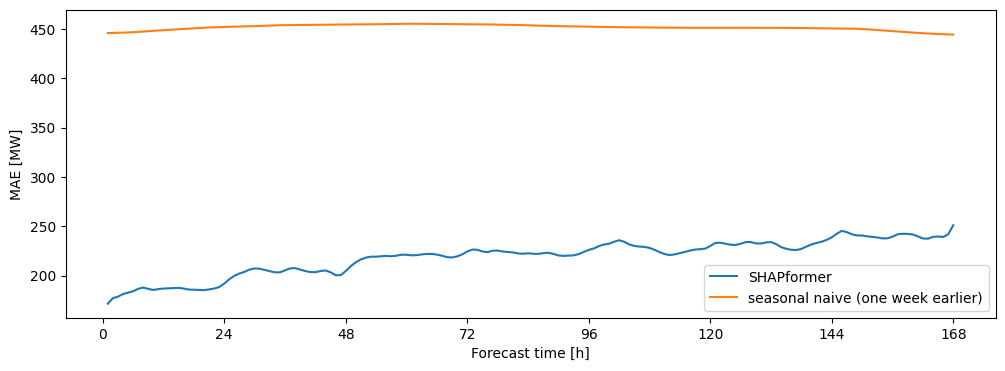

In [6]:
hours = np.arange(1, HORIZON + 1) / STEPS_PER_HOUR
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(hours, np.abs(predictions - actuals).mean(axis=0), label="SHAPformer")
ax.plot(hours, np.abs(naive - actuals).mean(axis=0), label="seasonal naive (one week earlier)")
ax.set_xticks(range(0, HORIZON // STEPS_PER_HOUR + 1, 24))
ax.set_xlabel("Forecast time [h]")
ax.set_ylabel("MAE [MW]")
ax.legend()
plt.show()

## Forecast one week

`model.predict(past, future)` takes the last `INPUT_LENGTH` time steps before the forecast (with the target and all covariates) as `past`, and the `HORIZON` time steps to forecast (with the covariates only) as `future`. Here, we forecast the week starting on Monday, 15 April 2019, and compare the forecast with the actual load.

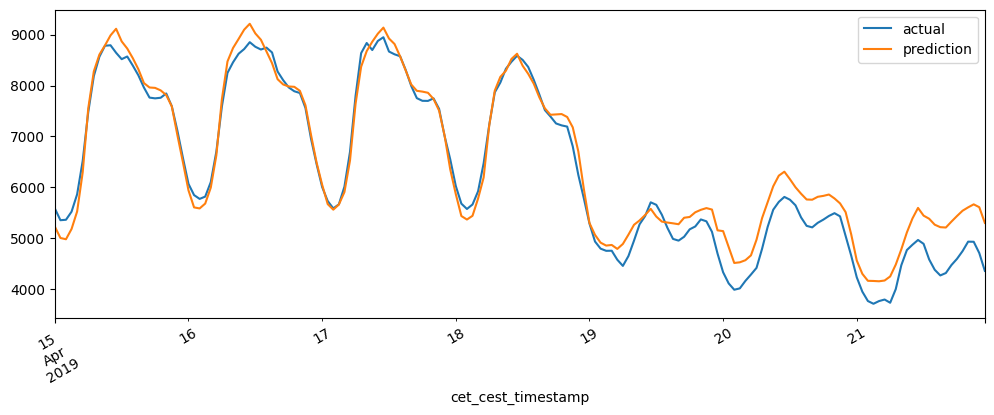

In [7]:
FORECAST_START = "2019-04-15 00:00:00+02:00"

start = df.index.get_loc(FORECAST_START)
past = df.iloc[start - INPUT_LENGTH:start]
future = df.iloc[start:start + HORIZON].drop(columns="load")

prediction = model.predict(past, future)

actual = df["load"].iloc[start:start + HORIZON]
comparison = pd.DataFrame({"actual": actual.to_numpy(), "prediction": prediction.to_numpy()},
                          index=pd.to_datetime(actual.index, utc=True).tz_convert("Europe/Berlin"))
comparison.plot(figsize=(12, 4), rot=30)
plt.show()

## Explain the forecast

`model.explain(past, future)` splits the forecast into contributions of the feature groups: one group per covariate and one group for the whole past load (`load`). As before, `base` + the sum of all `shap_values` = `prediction`. The explanation also contains `periods`: the name, length and first and last time step of each period of the past load. Since there is a single period, the past load is one feature like the covariates, and `periods` has a single row for the whole past week.

This forecast is explained with the exact method (`method="exact"`), which evaluates the model with all feature group subsets.

In [8]:
explanation = model.explain(past, future, method="exact")
print("max. |base + sum of SHAP values - prediction|:",
      (explanation["base"] + explanation["shap_values"].sum(axis=1) - explanation["prediction"]).abs().max())
explanation["periods"]

max. |base + sum of SHAP values - prediction|: 2.7284841053187847e-12


,length,start,end
name,,,
load,168,2019-04-08 00:00:00+02:00,2019-04-14 23:00:00+02:00


The explanation as a stacked area chart around the base value (dotted): positive contributions are stacked above the base, negative ones below it, so the forecast (solid line) lies between the upper and the lower edge of the stack. The dashed line is the actual load.

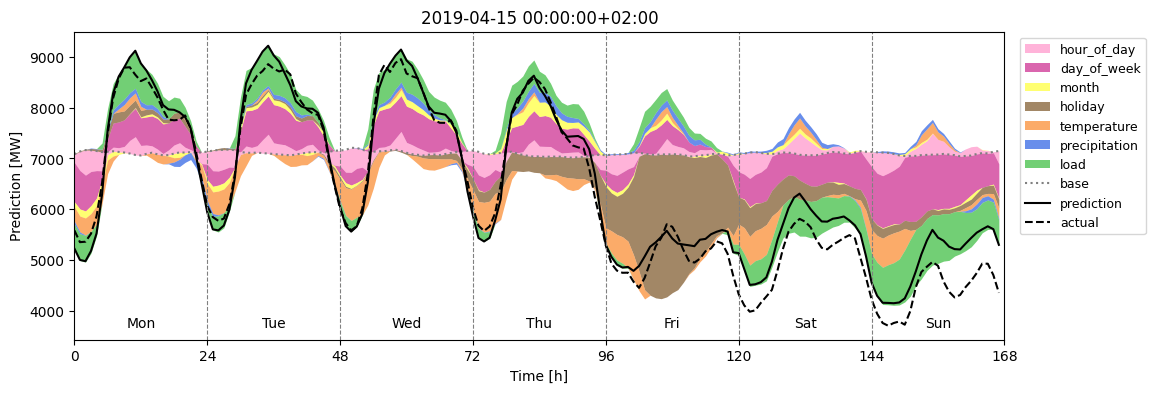

In [9]:
from src.plot import plot_explanation

plot_explanation(explanation, actual=actual, title=FORECAST_START)
plt.show()

## Dependence plots of many explanations

As in `training_dataframe.ipynb`: each dot is one explained forecast, with the feature value on the x-axis and its SHAP value at the forecasted time step `DEPENDENCE_HORIZON` (here 24 hours after the forecast start) on the y-axis. For the load, the x-axis is the load one week before that time step, and the y-axis the contribution of the past load.

We explain 1000 random forecast starts in the validation period with the permutation method (`method="permutation"`, 10 permutations each).

0.044 s per explanation on average


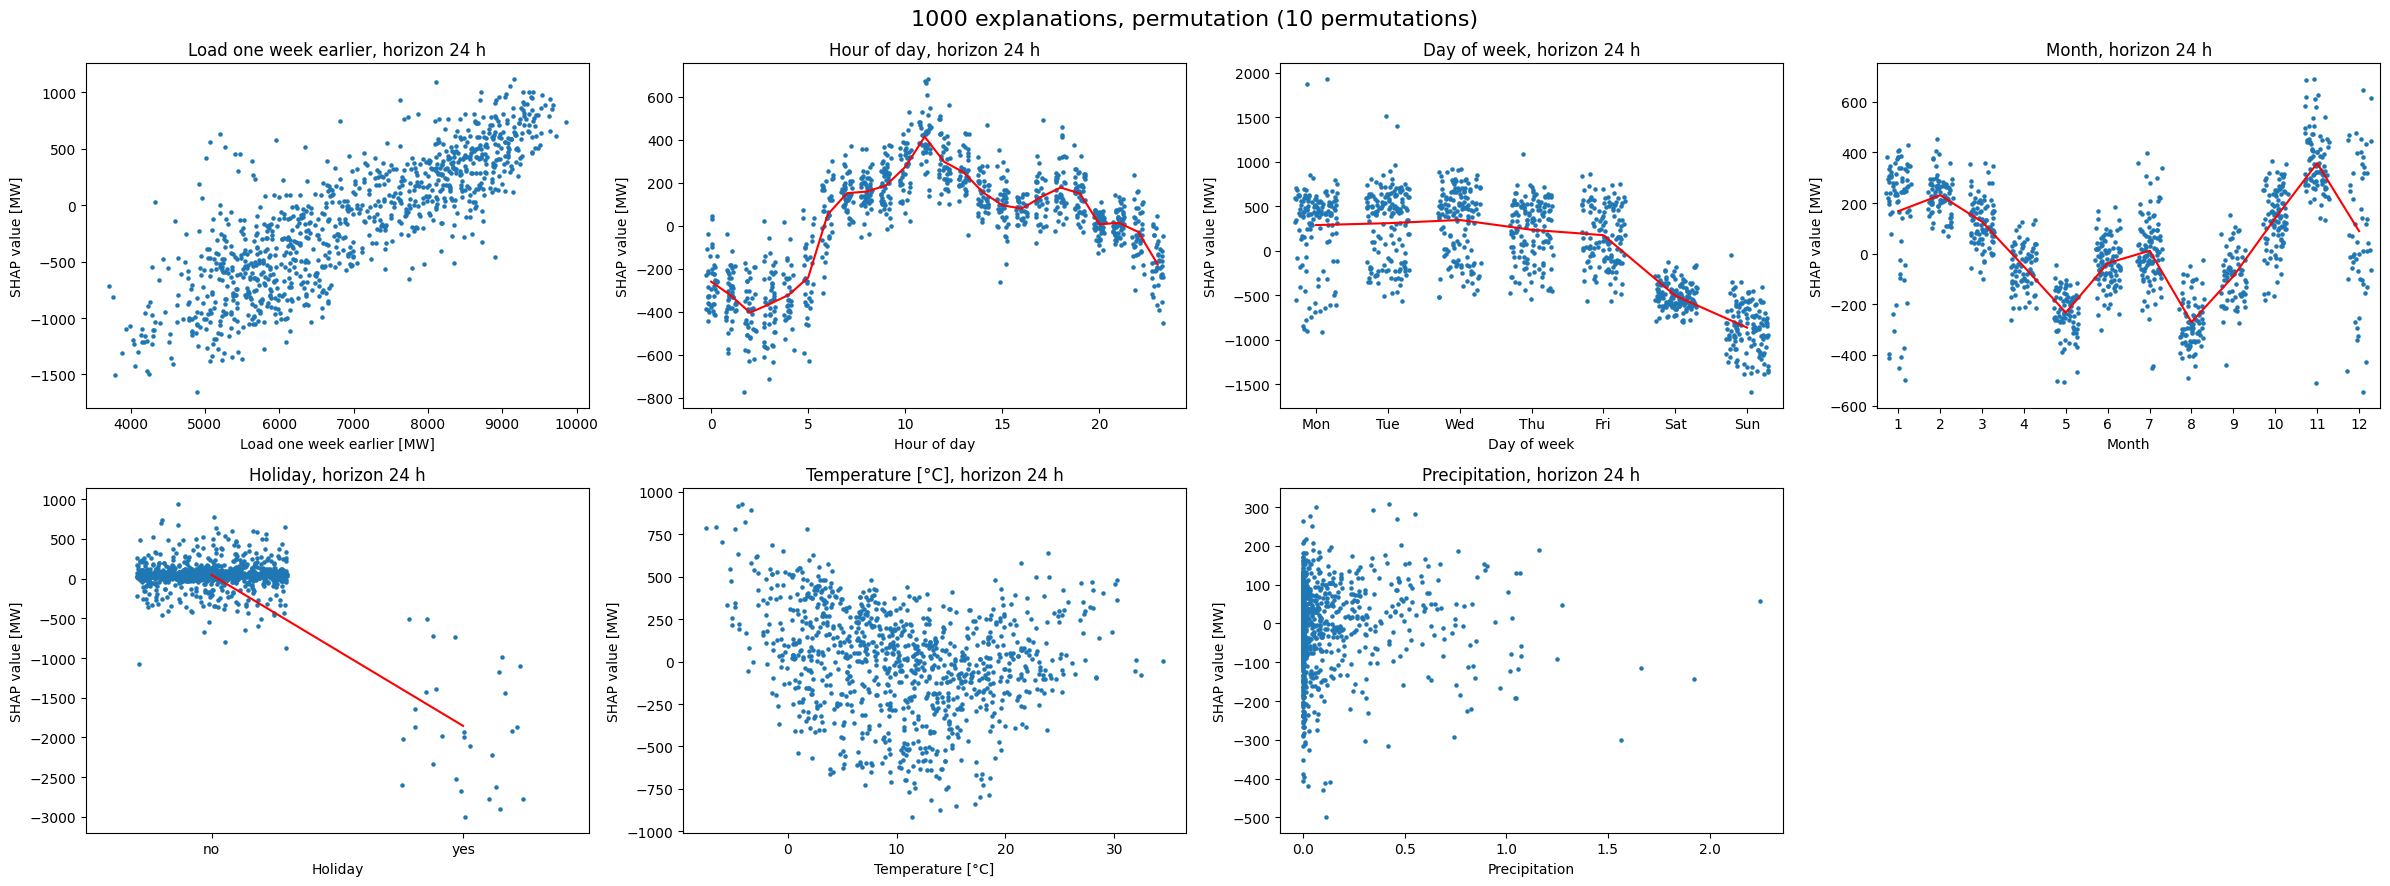

In [10]:
import math
import random
import time
from src.plot import plot_dependence

SEED = 42
N_PERMUTATIONS = 10  # permutations per explanation
DEPENDENCE_HORIZON = 24  # plot the SHAP values of this forecasted time step (24 hours after the start)
N_COLUMNS = 4

starts_1000 = random.Random(SEED).sample(evaluation_starts, 1000)

start_time = time.perf_counter()
explanations = [
    model.explain(df.iloc[s - INPUT_LENGTH:s], future_covariates.iloc[s:s + HORIZON], method="permutation",
                  n_permutations=N_PERMUTATIONS, seed=SEED + i, progress=False)
    for i, s in enumerate(starts_1000)
]
print(f"{(time.perf_counter() - start_time) / len(explanations):.3f} s per explanation on average")

n_rows = math.ceil(len(model.feature_names) / N_COLUMNS)
fig, axs = plt.subplots(n_rows, N_COLUMNS, figsize=(6 * N_COLUMNS, 4.5 * n_rows))
for ax, feature in zip(axs.flat, model.feature_names):
    plot_dependence(explanations, feature, horizon=DEPENDENCE_HORIZON, ax=ax)
for ax in axs.flat[len(model.feature_names):]:
    ax.set_visible(False)
fig.suptitle(f"1000 explanations, permutation ({N_PERMUTATIONS} permutations)", fontsize=16)
fig.tight_layout()
plt.show()

The mean absolute contribution of each feature group over the 1000 explanations and all forecasted time steps shows how much the model relies on each covariate and on the past load.

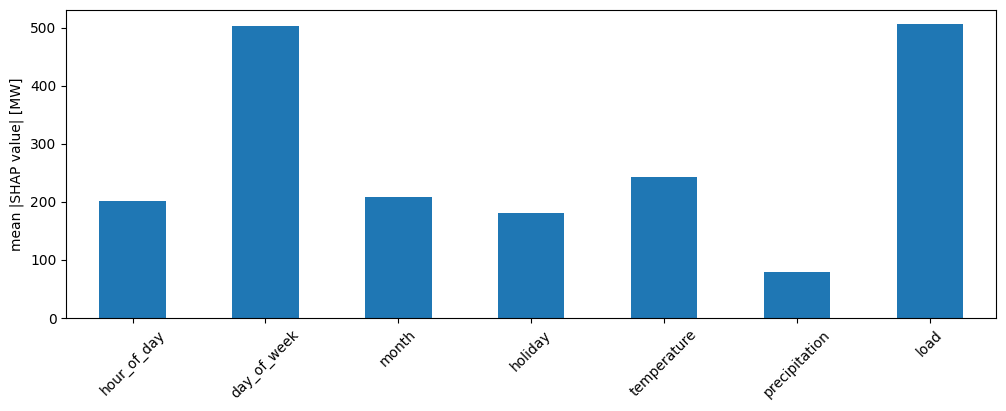

In [11]:
mean_abs = pd.concat([e["shap_values"].abs().mean() for e in explanations], axis=1).mean(axis=1)
ax = mean_abs.plot.bar(figsize=(12, 4), rot=45)
ax.set_ylabel("mean |SHAP value| [MW]")
plt.show()